# Phase 8 — Paper Figures
Generates all publication-ready figures at 600 DPI.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import matplotlib.ticker as ticker
from pathlib import Path
from collections import Counter
print('Imports successful')

Imports successful


In [2]:
BASE    = Path('E:/project1/EW_MOGA_Project')
RESULTS = BASE / 'results'
FIGURES = BASE / 'figures'
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],
    'font.size':11,'axes.labelsize':12,'axes.titlesize':12,
    'axes.titleweight':'bold','axes.labelweight':'bold',
    'axes.spines.top':False,'axes.spines.right':False,
    'savefig.dpi':600,'savefig.bbox':'tight',
    'savefig.facecolor':'white','figure.facecolor':'white',
})

COLORS = {'Standard_GA':'#C8504A','NSGA2_Parsimony':'#5B8C5A',
          'SHAP_RF':'#D99B3F','EW_MOGA':'#3E6FA3',
          'Boruta':'#7B4F9E','RFE':'#2E8B8B','mRMR':'#C47830'}
LIGHT  = {'Standard_GA':'#FFCDD2','NSGA2_Parsimony':'#C8E6C9',
          'SHAP_RF':'#FFE0B2','EW_MOGA':'#BBDEFB',
          'Boruta':'#E1D5F0','RFE':'#B2DFDF','mRMR':'#FFE5B4'}
LABELS = {'Standard_GA':'Standard GA','NSGA2_Parsimony':'NSGA-II Parsimony',
          'SHAP_RF':'SHAP-RF','EW_MOGA':'EW-MOGA (Proposed)',
          'Boruta':'Boruta','RFE':'RFE','mRMR':'mRMR'}

FEATURE_COLS = ['Mean','Variance','Standard Deviation','Entropy',
    'Skewness','Kurtosis','Contrast','Energy',
    'ASM','Homogeneity','Dissimilarity','Correlation','Coarseness']

print('Style configuration set')

Style configuration set


In [3]:
df_all = pd.read_csv(RESULTS / 'all_results_merged.csv')
print(f'Loaded results: {df_all.shape}')
print(f'Methods: {df_all.method.unique().tolist()}')

# Core methods order for main paper figures
CORE_ORDER = ['Standard_GA','NSGA2_Parsimony','SHAP_RF','EW_MOGA']
CORE_ORDER = [m for m in CORE_ORDER if m in df_all.method.unique()]

Loaded results: (105, 10)
Methods: ['EW_MOGA', 'Standard_GA', 'NSGA2_Parsimony', 'SHAP_RF', 'Boruta', 'RFE', 'mRMR']


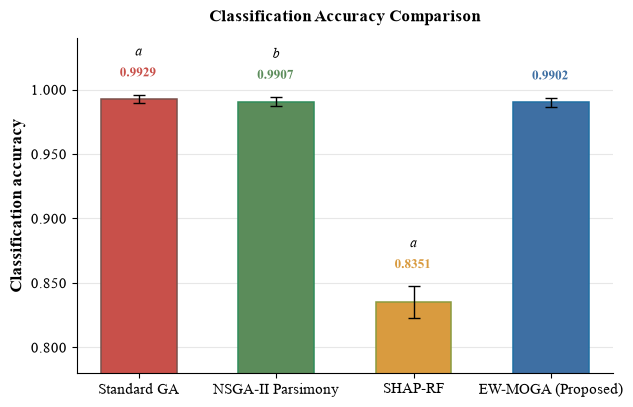

Saved fig1_accuracy


In [4]:
# ── Figure 1 — Accuracy comparison ───────────────────────────
MEANS = {m: df_all[df_all.method==m].accuracy.mean() for m in CORE_ORDER}
STDS  = {m: df_all[df_all.method==m].accuracy.std()  for m in CORE_ORDER}

fig, ax = plt.subplots(figsize=(6.5, 4.2))
x = np.arange(len(CORE_ORDER))
bars = ax.bar(x,
              [MEANS[m] for m in CORE_ORDER],
              yerr=[STDS[m] for m in CORE_ORDER],
              width=0.55,
              color=[COLORS[m] for m in CORE_ORDER],
              edgecolor=[c.replace('C8','7A').replace('5B','2F').replace('D9','8A').replace('3E','1F')
                         for c in [COLORS[m] for m in CORE_ORDER]],
              linewidth=1.1, capsize=4,
              error_kw=dict(elinewidth=1.0, capthick=1.0, ecolor='black'))

for i, m in enumerate(CORE_ORDER):
    top = MEANS[m] + STDS[m] + 0.012
    ax.annotate(f'{MEANS[m]:.4f}', xy=(i, top),
                ha='center', va='bottom', fontsize=9.5,
                fontweight='bold', color=COLORS[m],
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])

sig_letters = {'Standard_GA':'a','NSGA2_Parsimony':'b',
               'SHAP_RF':'a','EW_MOGA':''}
for i, m in enumerate(CORE_ORDER):
    letter = sig_letters.get(m,'')
    if letter:
        ax.text(i, MEANS[m]+STDS[m]+0.028, letter,
                ha='center', va='bottom', fontsize=10,
                style='italic', color='black')

ax.set_xticks(x)
ax.set_xticklabels([LABELS[m] for m in CORE_ORDER], fontsize=10.5)
ax.set_ylabel('Classification accuracy')
ax.set_ylim(0.78, 1.04)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
ax.set_title('Classification Accuracy Comparison', pad=12)

plt.tight_layout()
plt.savefig(FIGURES/'fig1_accuracy.png')
plt.savefig(FIGURES/'fig1_accuracy.pdf')
plt.show()
print('Saved fig1_accuracy')

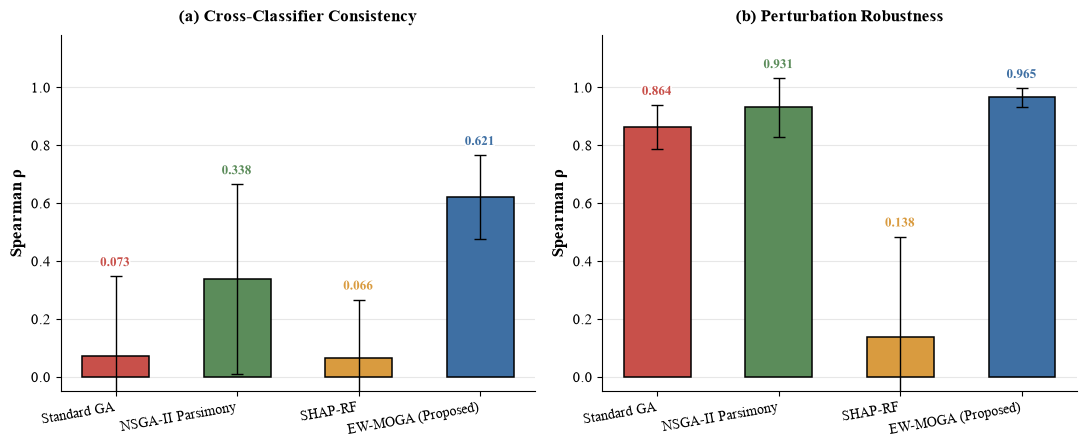

Saved fig2_audit


In [5]:
# ── Figure 2 — Audit metrics (CCC and PR) ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
audit_pairs = [('audit_ccc','(a) Cross-Classifier Consistency'),
               ('audit_pr', '(b) Perturbation Robustness')]

for ax, (col, title) in zip(axes, audit_pairs):
    means = [df_all[df_all.method==m][col].mean() for m in CORE_ORDER]
    stds  = [df_all[df_all.method==m][col].std()  for m in CORE_ORDER]
    x = np.arange(len(CORE_ORDER))
    ax.bar(x, means, yerr=stds, width=0.55,
           color=[COLORS[m] for m in CORE_ORDER],
           edgecolor='black', linewidth=1.1, capsize=4,
           error_kw=dict(elinewidth=1.0, capthick=1.0, ecolor='black'))
    for i, (m, mn, sd) in enumerate(zip(CORE_ORDER, means, stds)):
        ax.annotate(f'{mn:.3f}', xy=(i, mn+sd+0.025),
                    ha='center', va='bottom', fontsize=9.5,
                    fontweight='bold', color=COLORS[m],
                    path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[m] for m in CORE_ORDER], fontsize=10, rotation=10, ha='right')
    ax.set_ylabel('Spearman ρ')
    ax.set_ylim(-0.05, 1.18)
    ax.set_title(title, pad=10)
    ax.yaxis.grid(True, alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGURES/'fig2_audit.png', bbox_inches='tight')
plt.savefig(FIGURES/'fig2_audit.pdf', bbox_inches='tight')
plt.show()
print('Saved fig2_audit')

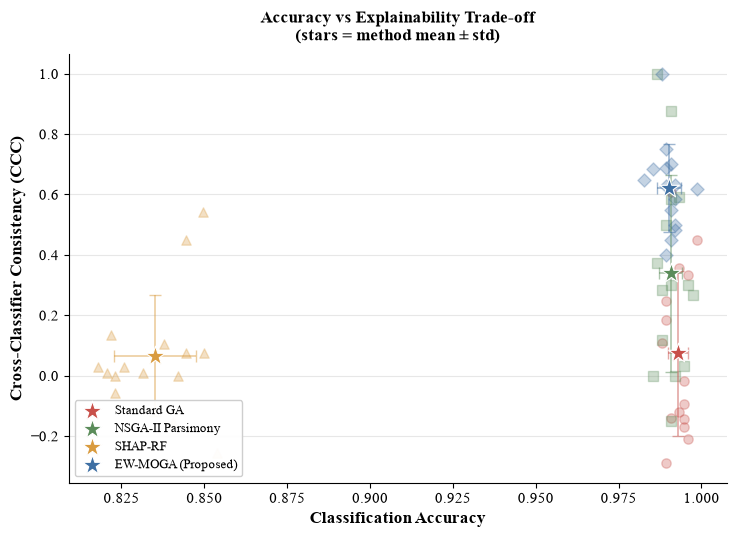

Saved fig3_tradeoff


In [6]:
# ── Figure 3 — Accuracy vs CCC trade-off ─────────────────────
fig, ax = plt.subplots(figsize=(7.5, 5.5))
markers = {'Standard_GA':'o','NSGA2_Parsimony':'s','SHAP_RF':'^','EW_MOGA':'D'}
for m in CORE_ORDER:
    sub = df_all[df_all.method==m]
    ax.scatter(sub.accuracy, sub.audit_ccc,
               color=COLORS[m], alpha=0.3, s=45,
               marker=markers.get(m,'o'), zorder=4)
    mx = sub.accuracy.mean()
    my = sub.audit_ccc.mean()
    ax.scatter(mx, my, color=COLORS[m], s=220, marker='*',
               edgecolors='white', linewidths=0.8,
               zorder=7, label=LABELS[m])
    ax.errorbar(mx, my, xerr=sub.accuracy.std(), yerr=sub.audit_ccc.std(),
                fmt='none', color=COLORS[m], capsize=4, linewidth=1.2,
                alpha=0.5, zorder=5)
ax.set_xlabel('Classification Accuracy')
ax.set_ylabel('Cross-Classifier Consistency (CCC)')
ax.set_title('Accuracy vs Explainability Trade-off\n(stars = method mean ± std)', pad=10)
ax.legend(loc='lower left', frameon=True, framealpha=0.95, fontsize=9)
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIGURES/'fig3_tradeoff.png')
plt.savefig(FIGURES/'fig3_tradeoff.pdf')
plt.show()
print('Saved fig3_tradeoff')

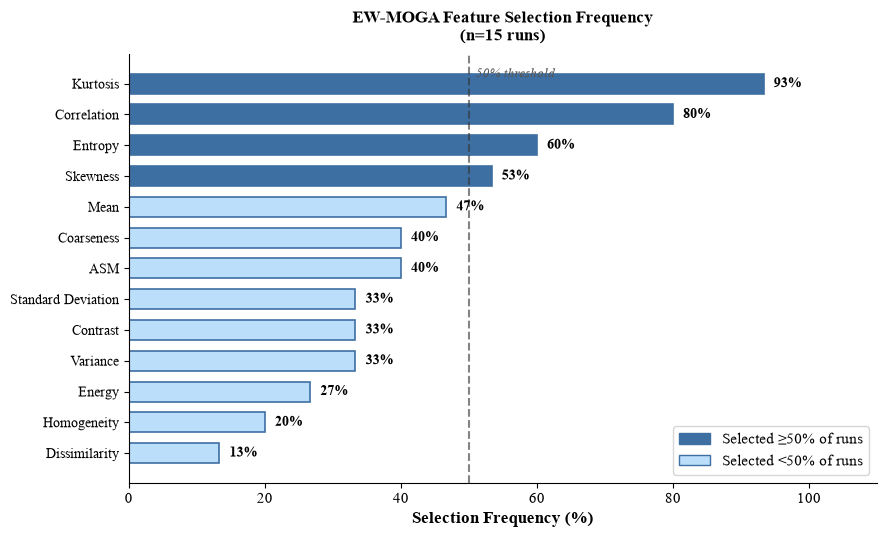

Saved fig4_features


In [7]:
# ── Figure 4 — Feature selection frequency ───────────────────
ew_rows = df_all[df_all.method=='EW_MOGA']
all_feats = []
for _, row in ew_rows.iterrows():
    if pd.notna(row['feature_names']) and row['feature_names']:
        all_feats.extend([f.strip() for f in str(row['feature_names']).split(',') if f.strip()])
feat_counts = Counter(all_feats)
total_ew = len(ew_rows)
feats = [f for f,_ in sorted(feat_counts.items(), key=lambda x: x[1])]
freqs = [feat_counts[f]/total_ew*100 for f in feats]
bcolors = [COLORS['EW_MOGA'] if v>=50 else LIGHT['EW_MOGA'] for v in freqs]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(range(len(feats)), freqs, color=bcolors,
               edgecolor=COLORS['EW_MOGA'], linewidth=1.2, height=0.65)
for bar, val in zip(bars, freqs):
    ax.text(val+1.5, bar.get_y()+bar.get_height()/2,
            f'{val:.0f}%', va='center', fontsize=10, fontweight='bold')
ax.axvline(x=50, color='#333333', linestyle='--', linewidth=1.5, alpha=0.6)
ax.text(51, len(feats)-0.5, '50% threshold', va='top', fontsize=9,
        color='#555555', style='italic')
ax.set_yticks(range(len(feats)))
ax.set_yticklabels(feats, fontsize=10)
ax.set_xlabel('Selection Frequency (%)')
ax.set_xlim(0, 110)
ax.set_title('EW-MOGA Feature Selection Frequency\n(n=15 runs)', pad=10)
p1 = mpatches.Patch(facecolor=COLORS['EW_MOGA'], edgecolor=COLORS['EW_MOGA'],
                    label='Selected ≥50% of runs')
p2 = mpatches.Patch(facecolor=LIGHT['EW_MOGA'],  edgecolor=COLORS['EW_MOGA'],
                    label='Selected <50% of runs')
ax.legend(handles=[p1,p2], loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig(FIGURES/'fig4_features.png')
plt.savefig(FIGURES/'fig4_features.pdf')
plt.show()
print('Saved fig4_features')

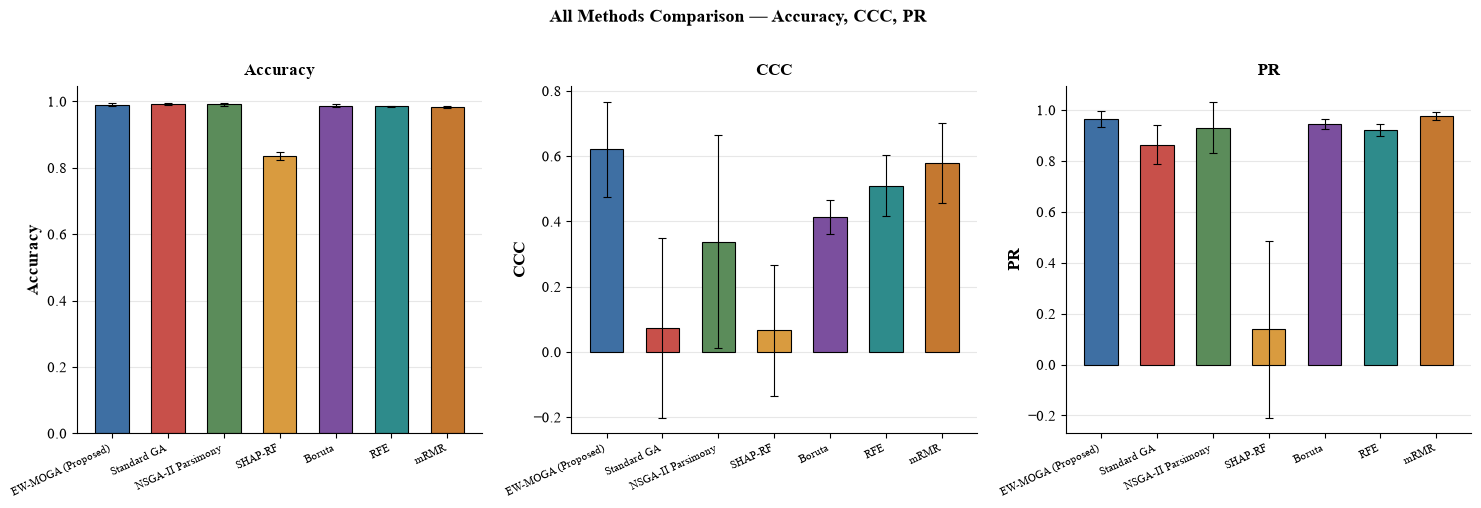

Saved fig5_all_methods


In [8]:
# ── Figure 5 — All methods comparison (extended) ─────────────
all_methods = [m for m in df_all.method.unique()]
metrics_plot = ['accuracy','audit_ccc','audit_pr']
metric_labels = ['Accuracy','CCC','PR']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, metric, mlabel in zip(axes, metrics_plot, metric_labels):
    means = [df_all[df_all.method==m][metric].mean() for m in all_methods]
    stds  = [df_all[df_all.method==m][metric].std()  for m in all_methods]
    colors_all = [COLORS.get(m,'#888888') for m in all_methods]
    x = np.arange(len(all_methods))
    ax.bar(x, means, yerr=stds, width=0.6,
           color=colors_all, edgecolor='black', linewidth=0.8,
           capsize=3, error_kw=dict(elinewidth=0.8, capthick=0.8, ecolor='black'))
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS.get(m,m) for m in all_methods],
                       fontsize=8, rotation=25, ha='right')
    ax.set_ylabel(mlabel)
    ax.set_title(mlabel, pad=8)
    ax.yaxis.grid(True, alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle('All Methods Comparison — Accuracy, CCC, PR',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES/'fig5_all_methods.png', bbox_inches='tight')
plt.savefig(FIGURES/'fig5_all_methods.pdf', bbox_inches='tight')
plt.show()
print('Saved fig5_all_methods')

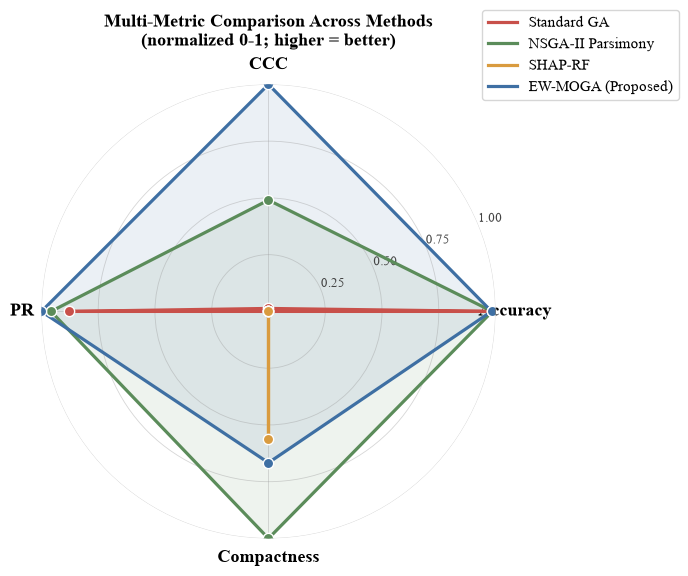

Saved fig6_radar


In [9]:
# ── Figure 6 — Radar chart ───────────────────────────────────
import math
metric_names = ['Accuracy','CCC','PR','Compactness']
N = len(metric_names)
theta = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
theta += theta[:1]

method_vals = {}
for m in CORE_ORDER:
    sub = df_all[df_all.method==m]
    method_vals[m] = [sub.accuracy.mean(), sub.audit_ccc.mean(),
                      sub.audit_pr.mean(), 1-(sub.n_features.mean()/13)]

all_v  = np.array(list(method_vals.values()))
mins   = all_v.min(axis=0)
maxs   = all_v.max(axis=0)
ranges = np.where(maxs-mins==0, 1, maxs-mins)

fig, ax = plt.subplots(figsize=(7.5,7.5), subplot_kw=dict(polar=True))
for m in CORE_ORDER:
    raw    = method_vals[m]
    normed = ((np.array(raw)-mins)/ranges).tolist()
    normed += normed[:1]
    ax.plot(theta, normed, color=COLORS[m], linewidth=2.3,
            label=LABELS[m], zorder=5)
    ax.fill(theta, normed, color=COLORS[m], alpha=0.1)
    ax.scatter(theta[:-1], normed[:-1], color=COLORS[m],
               s=55, edgecolors='white', linewidths=1.0, zorder=6)
ax.set_xticks(theta[:-1])
ax.set_xticklabels(metric_names, fontsize=13, fontweight='bold')
ax.set_ylim(0,1)
ax.set_yticks([0.25,0.5,0.75,1.0])
ax.set_yticklabels(['0.25','0.50','0.75','1.00'], fontsize=9, color='#444444')
ax.yaxis.grid(True, color='#999999', alpha=0.4, linewidth=0.6)
ax.xaxis.grid(True, color='#999999', alpha=0.4, linewidth=0.6)
ax.spines['polar'].set_visible(False)
ax.set_title('Multi-Metric Comparison Across Methods\n(normalized 0-1; higher = better)',
             pad=28, fontsize=13, fontweight='bold')
ax.legend(loc='upper right', bbox_to_anchor=(1.42,1.18), frameon=True, fontsize=10.5)
plt.tight_layout()
plt.savefig(FIGURES/'fig6_radar.png', bbox_inches='tight')
plt.savefig(FIGURES/'fig6_radar.pdf', bbox_inches='tight')
plt.show()
print('Saved fig6_radar')

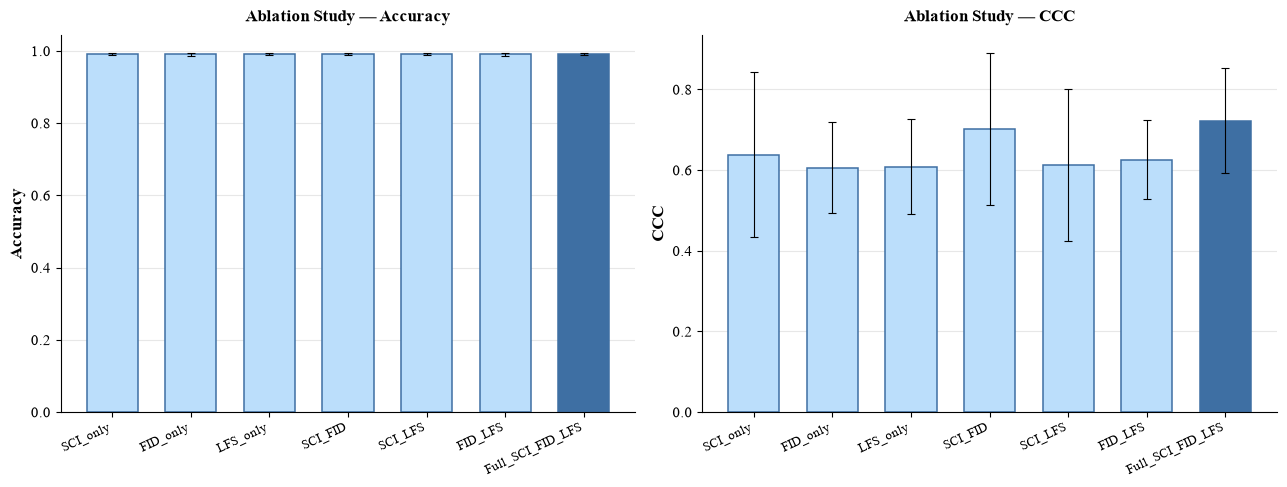

Saved fig7_ablation


In [10]:
# ── Figure 7 — Ablation study ────────────────────────────────
abl_path = RESULTS / 'ablation' / 'ablation_results.csv'
if abl_path.exists():
    df_abl = pd.read_csv(abl_path)
    variant_order = ['SCI_only','FID_only','LFS_only',
                     'SCI_FID','SCI_LFS','FID_LFS','Full_SCI_FID_LFS']
    variant_order = [v for v in variant_order if v in df_abl.variant.unique()]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (col, title) in zip(axes, [('accuracy','Accuracy'),
                                        ('audit_ccc','CCC')]):
        means = [df_abl[df_abl.variant==v][col].mean() for v in variant_order]
        stds  = [df_abl[df_abl.variant==v][col].std()  for v in variant_order]
        colors_abl = [COLORS['EW_MOGA'] if v=='Full_SCI_FID_LFS'
                      else LIGHT['EW_MOGA'] for v in variant_order]
        x = np.arange(len(variant_order))
        ax.bar(x, means, yerr=stds, width=0.65,
               color=colors_abl, edgecolor=COLORS['EW_MOGA'],
               linewidth=1.1, capsize=3,
               error_kw=dict(elinewidth=0.8, capthick=0.8, ecolor='black'))
        ax.set_xticks(x)
        ax.set_xticklabels(variant_order, fontsize=9, rotation=25, ha='right')
        ax.set_ylabel(title)
        ax.set_title(f'Ablation Study — {title}', pad=10)
        ax.yaxis.grid(True, alpha=0.3)
        ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(FIGURES/'fig7_ablation.png', bbox_inches='tight')
    plt.savefig(FIGURES/'fig7_ablation.pdf', bbox_inches='tight')
    plt.show()
    print('Saved fig7_ablation')
else:
    print('Ablation results not found — run Notebook 4 first')

In [11]:
print('='*55)
print('All figures saved to:', FIGURES)
print('='*55)
import os
for f in sorted(FIGURES.glob('*.png')):
    size_kb = f.stat().st_size / 1024
    print(f'  {f.name:<45} {size_kb:>6.1f} KB')
print()
print('Notebook 8 complete — ready to run Notebook 9')

All figures saved to: E:\project1\EW_MOGA_Project\figures
  class_distribution.png                          93.8 KB
  feature_correlation.png                        356.1 KB
  feature_separability.png                       543.3 KB
  fig1_accuracy.png                              206.7 KB
  fig2_audit.png                                 378.2 KB
  fig3_tradeoff.png                              415.7 KB
  fig4_features.png                              407.9 KB
  fig5_all_methods.png                           386.6 KB
  fig6_radar.png                                 663.0 KB
  fig7_ablation.png                              344.1 KB
  figA_dataset_distributions.png                 430.4 KB

Notebook 8 complete — ready to run Notebook 9
